# Manhattan Tiny OCR Verification

Visual verification of OCR detections from the Manhattan 8K tiny test run.
Each image is shown with detected text bounding boxes overlaid to identify potential hallucinations.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path
from IPython.display import display, HTML

# Configuration
PARQUET_PATH = "/share/ju/matt/mllmsci/outputs/ocr_manhattan_tiny/detections.parquet"

# Load data
df = pd.read_parquet(PARQUET_PATH)
print(f"Total detection rows: {len(df)}")
print(f"Unique images: {df['image_path'].nunique()}")
print(f"Columns: {df.columns.tolist()}")


Total detection rows: 364
Unique images: 4
Columns: ['sample_id', 'image_path', 'location_group', 'location_id', 'face', 'ts_processed', 'tile_idx', 'tile_row', 'tile_col', 'n_tiles_x', 'n_tiles_y', 'bbox_max_x', 'bbox_max_y', 'text', 'bbox_x1', 'bbox_y1', 'bbox_x2', 'bbox_y2', 'confidence', 'confidence_numeric', 'text_type', 'detection_count']


## Summary Statistics


In [2]:
# Quick summary
print("=== DETECTION SUMMARY ===")
detections_per_image = df[df['text'].notna()].groupby('image_path').size()
print(f"Total images: {df['image_path'].nunique()}")
print(f"Total detections (with text): {df['text'].notna().sum()}")
print(f"Detections per image: min={detections_per_image.min()}, max={detections_per_image.max()}, mean={detections_per_image.mean():.1f}")

# Confidence distribution
if 'confidence' in df.columns:
    print(f"\n=== CONFIDENCE DISTRIBUTION ===")
    print(df['confidence'].value_counts())

# Text type distribution
if 'text_type' in df.columns:
    print(f"\n=== TEXT TYPE DISTRIBUTION ===")
    print(df['text_type'].value_counts())

# All detected texts
print(f"\n=== ALL DETECTED TEXTS ({df['text'].notna().sum()} total) ===")
for _, row in df[df['text'].notna()].iterrows():
    face = Path(row['image_path']).stem
    conf = row.get('confidence', '?')
    print(f"  [{face}] [{conf}] '{row['text']}'")


=== DETECTION SUMMARY ===
Total images: 4
Total detections (with text): 69
Detections per image: min=10, max=34, mean=17.2

=== CONFIDENCE DISTRIBUTION ===
confidence
high        57
low          7
moderate     4
perfect      1
Name: count, dtype: int64

=== TEXT TYPE DISTRIBUTION ===
text_type
sign               38
street_name         8
graffiti            7
billboard           6
building_number     5
storefront          4
vehicle             1
Name: count, dtype: int64

=== ALL DETECTED TEXTS (69 total) ===
  [R] [high] 'RS ONLY'
  [R] [high] 'One Way'
  [R] [high] '6'
  [R] [high] 'No Parking'
  [R] [high] 'NO PARKING'
  [R] [high] '6'
  [R] [high] '100'
  [B] [high] 'ROAD MAY FLOOD'
  [B] [high] 'IF FLOOD WARNING USE ALT ROUTE'
  [B] [high] '1 Av'
  [B] [high] 'MT25'
  [B] [high] '12'-11"'
  [B] [high] 'CLEARANCE'
  [B] [high] 'WILLIS AVE'
  [B] [high] 'BR'
  [B] [high] 'STOP'
  [B] [high] 'KEEP OUT'
  [B] [high] 'CITY PA'
  [B] [high] 'RBD'
  [L] [high] 'Legend SD'
  [L] [high] 'KE

## Visual Verification

Each image is shown with detected bounding boxes. **Red boxes indicate potential hallucinations** if you can't find the text in that location.


In [3]:
def visualize_detections_detailed(image_path, detections_df, figsize=(20, 20)):
    """Visualize OCR detections on an image with detailed labels."""
    
    # Load image
    img = Image.open(image_path)
    img_width, img_height = img.size
    
    # Get coordinate range from data
    if len(detections_df) > 0 and 'bbox_max_x' in detections_df.columns:
        bbox_max_x = detections_df['bbox_max_x'].iloc[0]
        bbox_max_y = detections_df['bbox_max_y'].iloc[0]
    else:
        bbox_max_x = bbox_max_y = 999
    
    # Filter to actual detections
    dets = detections_df[detections_df['text'].notna()]
    
    fig, ax = plt.subplots(1, 1, figsize=figsize)
    ax.imshow(img)
    
    # Color map by confidence
    conf_colors = {
        'perfect': 'lime',
        'very_high': 'green',
        'high': 'yellow',
        'moderate': 'orange',
        'low': 'red',
        'very_low': 'darkred',
    }
    
    print(f"\n{'='*60}")
    print(f"IMAGE: {Path(image_path).name} ({img_width}x{img_height})")
    print(f"DETECTIONS: {len(dets)}")
    print(f"{'='*60}")
    
    for i, (_, row) in enumerate(dets.iterrows()):
        # Skip if no bbox
        if pd.isna(row.get('bbox_x1')):
            continue
            
        # Convert global coords to pixel coords
        x1 = row['bbox_x1'] / bbox_max_x * img_width
        y1 = row['bbox_y1'] / bbox_max_y * img_height
        x2 = row['bbox_x2'] / bbox_max_x * img_width
        y2 = row['bbox_y2'] / bbox_max_y * img_height
        
        width = x2 - x1
        height = y2 - y1
        
        # Get color based on confidence
        conf = row.get('confidence', 'moderate')
        color = conf_colors.get(conf, 'red')
        
        # Draw rectangle
        rect = patches.Rectangle((x1, y1), width, height, 
                                   linewidth=3, edgecolor=color, facecolor='none')
        ax.add_patch(rect)
        
        # Add number label
        ax.text(x1, y1-10, str(i+1), fontsize=14, color=color, fontweight='bold',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))
        
        # Print detection details
        text_type = row.get('text_type', '?')
        print(f"  [{i+1}] [{conf}] [{text_type}] '{row['text']}'")
        print(f"      bbox: ({row['bbox_x1']:.0f}, {row['bbox_y1']:.0f}) -> ({row['bbox_x2']:.0f}, {row['bbox_y2']:.0f})")
        print(f"      pixel: ({x1:.0f}, {y1:.0f}) -> ({x2:.0f}, {y2:.0f})")
    
    ax.set_title(f"{Path(image_path).name} - {len(dets)} detections", fontsize=16)
    ax.axis('off')
    
    # Legend
    legend_patches = [patches.Patch(color=c, label=l) for l, c in conf_colors.items()]
    ax.legend(handles=legend_patches, loc='upper right', fontsize=10)
    
    plt.tight_layout()
    plt.show()
    
    return dets


## Verify Each Face

Running through all 4 faces (B, F, L, R) to visually check detections.


Processing 4 images...

IMAGE: B.jpg (8192x8192)
DETECTIONS: 12
  [1] [high] [sign] 'ROAD MAY FLOOD'
      bbox: (425, 3897) -> (574, 4055)
      pixel: (387, 3551) -> (523, 3695)
  [2] [high] [sign] 'IF FLOOD WARNING USE ALT ROUTE'
      bbox: (393, 4103) -> (594, 4163)
      pixel: (358, 3738) -> (541, 3793)
  [3] [high] [street_name] '1 Av'
      bbox: (303, 4083) -> (365, 4110)
      pixel: (276, 3720) -> (333, 3745)
  [4] [high] [sign] 'MT25'
      bbox: (84, 4173) -> (168, 4201)
      pixel: (77, 3802) -> (153, 3828)
  [5] [high] [sign] '12'-11"'
      bbox: (1154, 3526) -> (1294, 3582)
      pixel: (1051, 3213) -> (1179, 3264)
  [6] [high] [sign] 'CLEARANCE'
      bbox: (1166, 3573) -> (1287, 3601)
      pixel: (1062, 3255) -> (1173, 3281)
  [7] [high] [street_name] 'WILLIS AVE'
      bbox: (168, 4273) -> (351, 4323)
      pixel: (153, 3893) -> (320, 3939)
  [8] [high] [street_name] 'BR'
      bbox: (286, 4323) -> (328, 4351)
      pixel: (261, 3939) -> (299, 3964)
  [9] [high] 

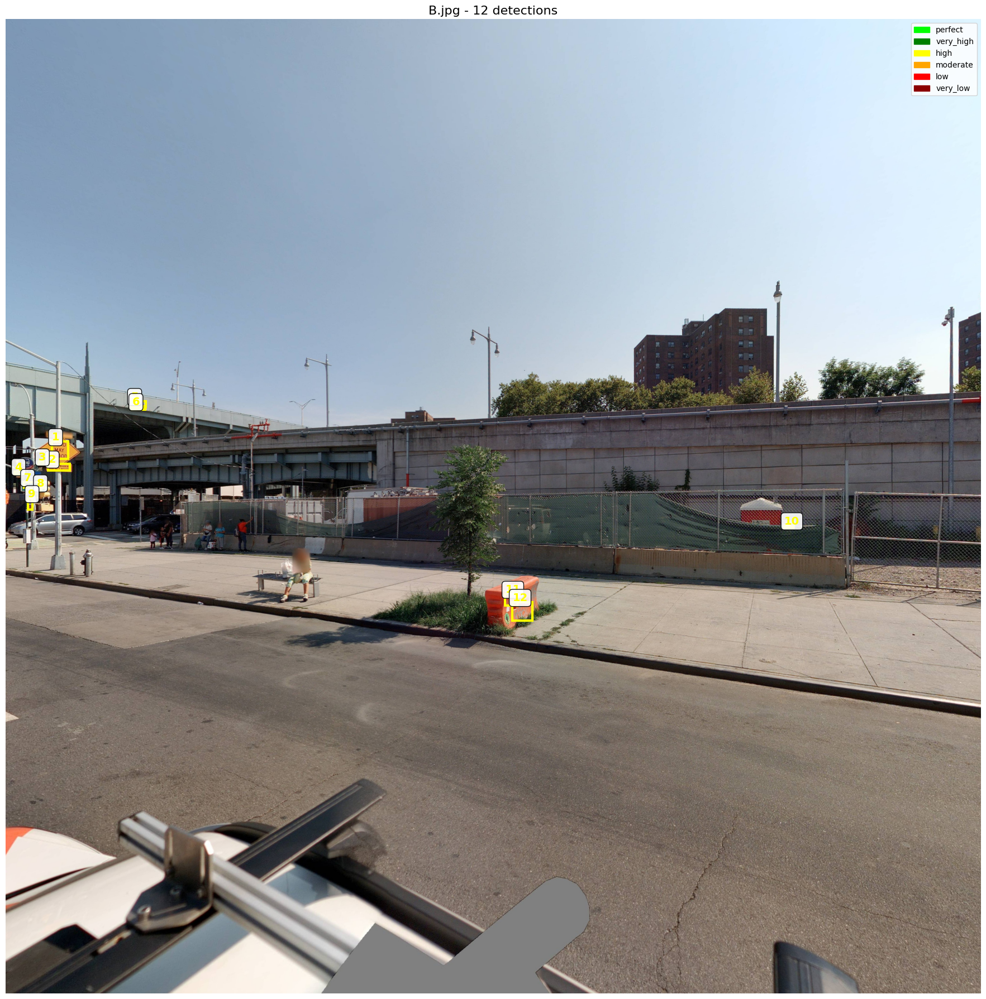


IMAGE: F.jpg (8192x8192)
DETECTIONS: 13
  [1] [high] [billboard] 'HardWear by Tiffany'
      bbox: (4709, 2497) -> (5044, 2697)
      pixel: (4291, 2275) -> (4596, 2457)
  [2] [high] [billboard] 'LOVE'
      bbox: (5063, 2472) -> (5269, 2906)
      pixel: (4613, 2252) -> (4801, 2648)
  [3] [high] [billboard] 'TI'
      bbox: (5286, 2735) -> (5338, 2827)
      pixel: (4816, 2492) -> (4864, 2576)
  [4] [high] [billboard] 'With love, Since 1837'
      bbox: (5322, 2678) -> (5555, 2820)
      pixel: (4849, 2440) -> (5061, 2569)
  [5] [high] [billboard] 'TIFFANY&CO.'
      bbox: (5286, 2737) -> (5588, 2928)
      pixel: (4816, 2494) -> (5091, 2668)
  [6] [high] [billboard] 'OUTFRONT'
      bbox: (5468, 3101) -> (5574, 3158)
      pixel: (4982, 2825) -> (5079, 2877)
  [7] [perfect] [sign] 'No Parking'
      bbox: (2636, 4198) -> (2692, 4229)
      pixel: (2402, 3825) -> (2453, 3853)
  [8] [high] [sign] 'NO PARKING'
      bbox: (2602, 4214) -> (2645, 4270)
      pixel: (2371, 3840) -> (2410,

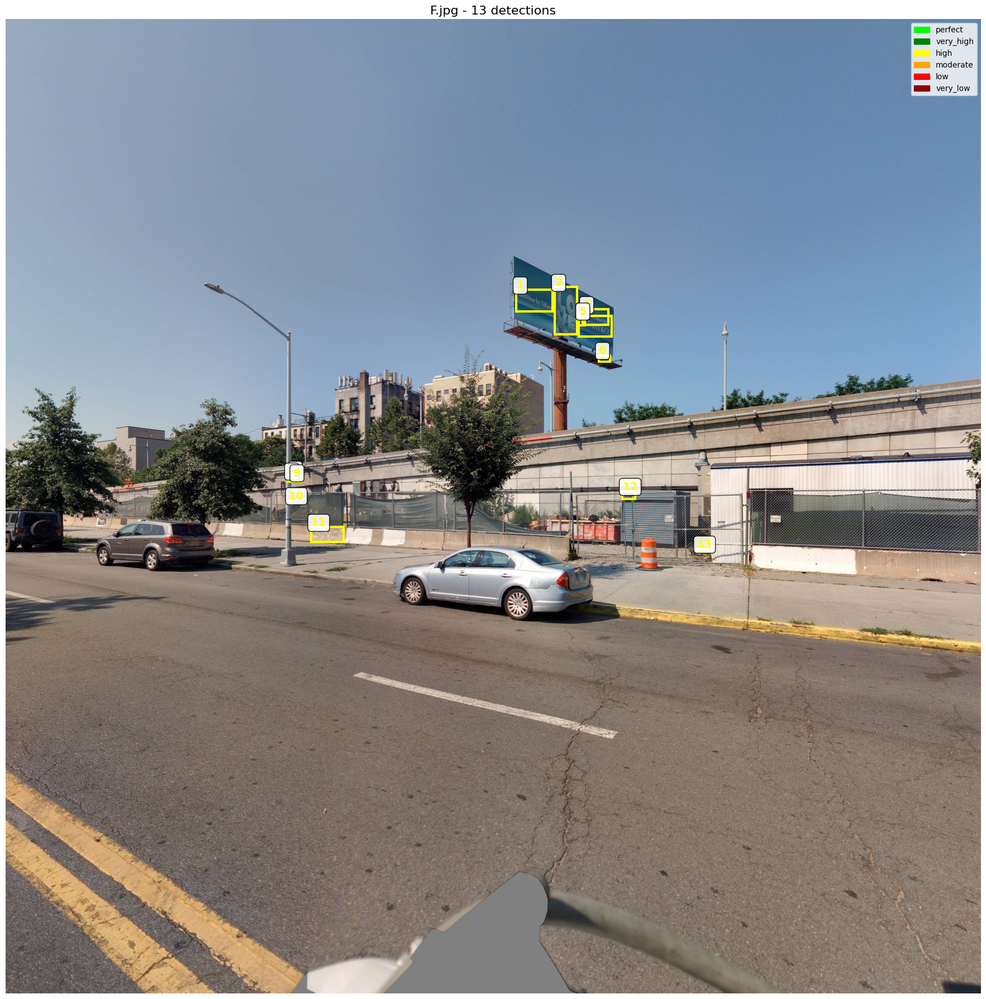


IMAGE: L.jpg (8192x8192)
DETECTIONS: 10
  [1] [high] [sign] 'Legend SD'
      bbox: (4462, 4015) -> (4591, 4055)
      pixel: (4065, 3658) -> (4183, 3695)
  [2] [high] [sign] 'KEEP OUT'
      bbox: (320, 4703) -> (410, 4728)
      pixel: (292, 4285) -> (374, 4308)
  [3] [high] [vehicle] '1976'
      bbox: (4211, 4759) -> (4284, 4799)
      pixel: (3837, 4336) -> (3903, 4373)
  [4] [high] [building_number] '526'
      bbox: (4289, 4396) -> (4361, 4441)
      pixel: (3908, 4005) -> (3973, 4046)
  [5] [high] [building_number] '197617'
      bbox: (4214, 4757) -> (4337, 4800)
      pixel: (3840, 4334) -> (3952, 4373)
  [6] [high] [sign] '314727'
      bbox: (6254, 4439) -> (6303, 4459)
      pixel: (5698, 4045) -> (5743, 4063)
  [7] [high] [sign] 'XTRA'
      bbox: (7887, 4336) -> (7982, 4360)
      pixel: (7186, 3951) -> (7273, 3973)
  [8] [high] [sign] 'XTRA'
      bbox: (7791, 4330) -> (7831, 4403)
      pixel: (7099, 3945) -> (7135, 4012)
  [9] [high] [sign] 'XTRA'
      bbox: (7887, 

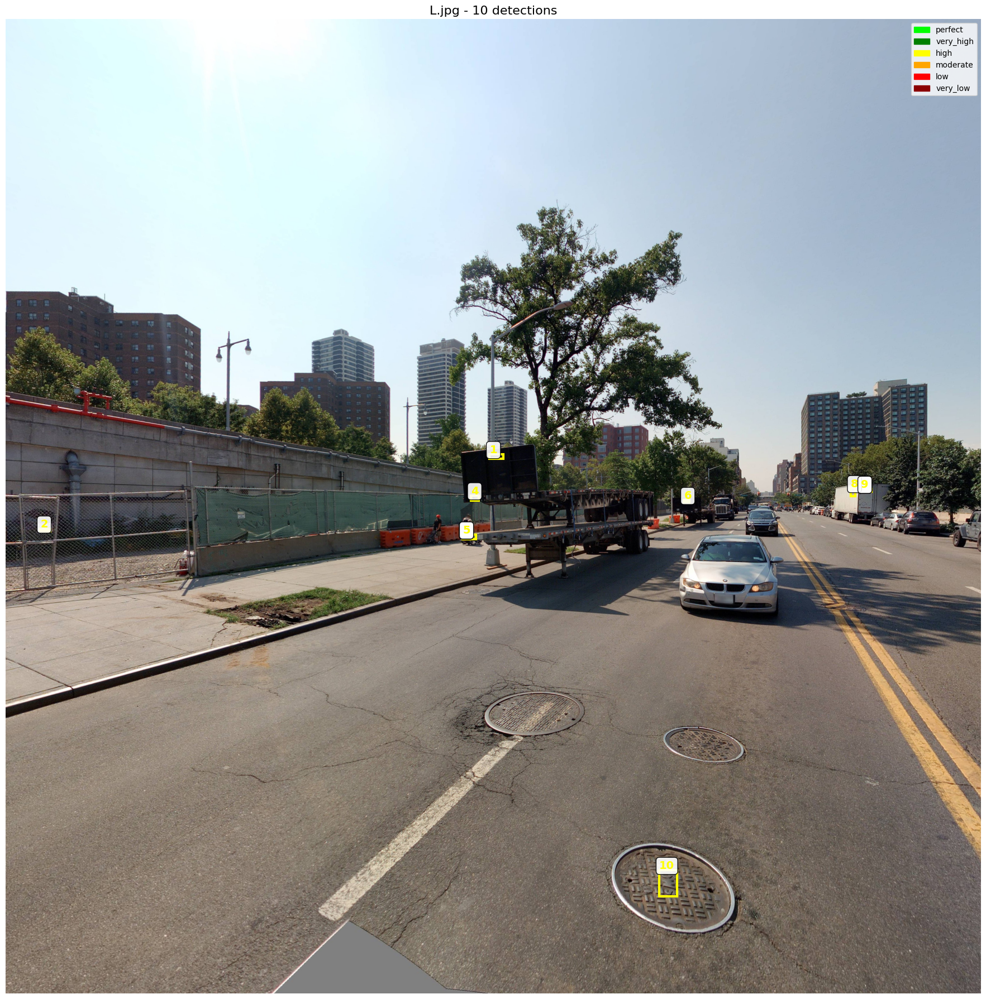


IMAGE: R.jpg (8192x8192)
DETECTIONS: 34
  [1] [high] [sign] 'RS ONLY'
      bbox: (7375, 4259) -> (7487, 4302)
      pixel: (6720, 3881) -> (6822, 3920)
  [2] [high] [sign] 'One Way'
      bbox: (7521, 4270) -> (7599, 4302)
      pixel: (6853, 3891) -> (6924, 3920)
  [3] [high] [building_number] '6'
      bbox: (8151, 4400) -> (8168, 4426)
      pixel: (7427, 4009) -> (7442, 4033)
  [4] [high] [sign] 'No Parking'
      bbox: (7991, 4230) -> (8093, 4313)
      pixel: (7281, 3854) -> (7374, 3930)
  [5] [high] [sign] 'NO PARKING'
      bbox: (7987, 4231) -> (8096, 4316)
      pixel: (7277, 3855) -> (7377, 3932)
  [6] [high] [building_number] '6'
      bbox: (8148, 4400) -> (8167, 4428)
      pixel: (7424, 4009) -> (7441, 4034)
  [7] [high] [sign] '100'
      bbox: (8392, 4385) -> (8505, 4413)
      pixel: (7646, 3995) -> (7749, 4021)
  [8] [high] [street_name] '1 Av'
      bbox: (3979, 3946) -> (4091, 4002)
      pixel: (3625, 3595) -> (3727, 3646)
  [9] [high] [street_name] '125 St'
   

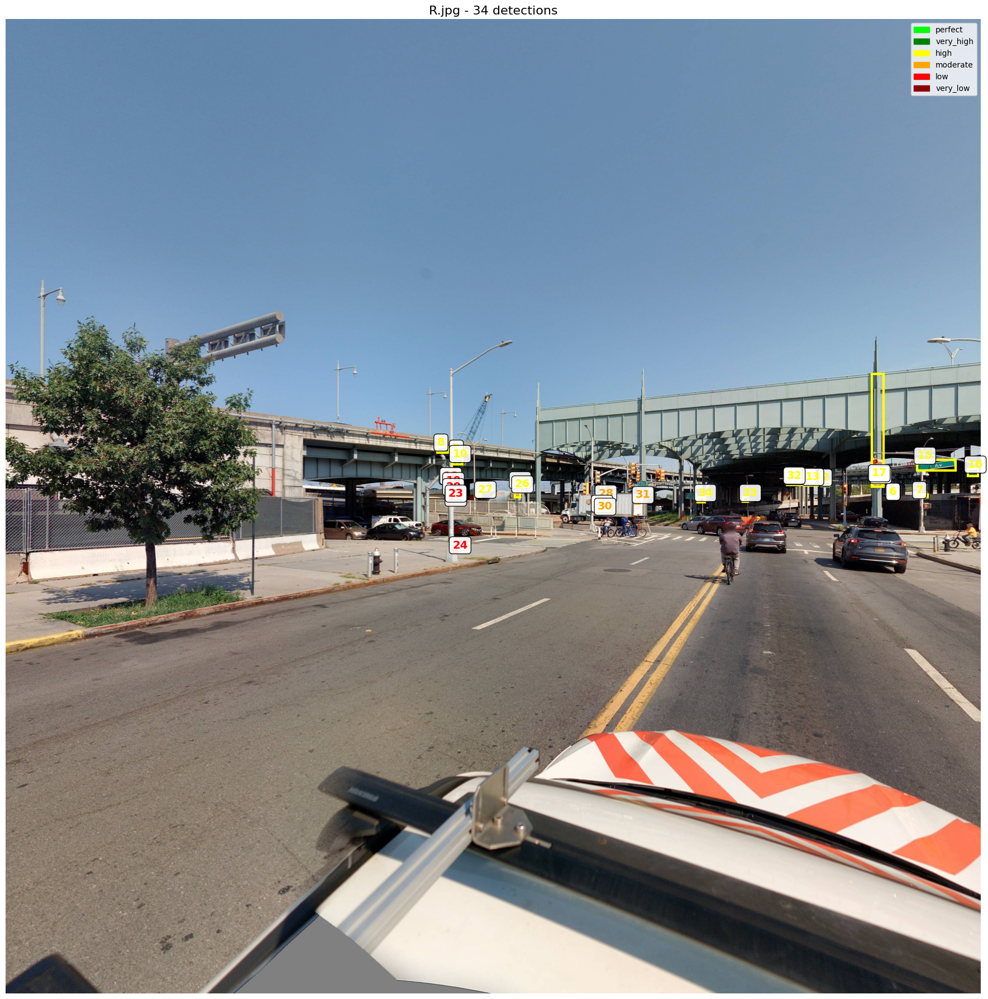

In [4]:
# Visualize all faces
unique_images = df['image_path'].unique()
print(f"Processing {len(unique_images)} images...")

for img_path in sorted(unique_images):
    img_df = df[df['image_path'] == img_path]
    visualize_detections_detailed(img_path, img_df, figsize=(18, 18))


## Coordinate System Analysis

The 8192x8192 images are tiled to 1024x1024. Check the coordinate system being used.


In [5]:
# Analyze coordinate system
print("=== COORDINATE SYSTEM ===")
print(f"bbox_max_x: {df['bbox_max_x'].unique()}")
print(f"bbox_max_y: {df['bbox_max_y'].unique()}")
print(f"n_tiles_x: {df['n_tiles_x'].unique()}")
print(f"n_tiles_y: {df['n_tiles_y'].unique()}")

# Bbox ranges
dets = df[df['text'].notna()]
if len(dets) > 0:
    print(f"\n=== BBOX RANGES (actual detections) ===")
    print(f"bbox_x1: min={dets['bbox_x1'].min():.0f}, max={dets['bbox_x1'].max():.0f}")
    print(f"bbox_y1: min={dets['bbox_y1'].min():.0f}, max={dets['bbox_y1'].max():.0f}")
    print(f"bbox_x2: min={dets['bbox_x2'].min():.0f}, max={dets['bbox_x2'].max():.0f}")
    print(f"bbox_y2: min={dets['bbox_y2'].min():.0f}, max={dets['bbox_y2'].max():.0f}")
    
    # Expected for 8x8 tiles with 0-999 per tile: max should be ~7999
    expected_max = (8 * 999)
    print(f"\nExpected max for 8x8 tiles: {expected_max}")
else:
    print("No detections with text found!")


=== COORDINATE SYSTEM ===
bbox_max_x: [8991]
bbox_max_y: [8991]
n_tiles_x: [9]
n_tiles_y: [9]

=== BBOX RANGES (actual detections) ===
bbox_x1: min=84, max=8872
bbox_y1: min=2472, max=7853
bbox_x2: min=168, max=8967
bbox_y2: min=2697, max=8093

Expected max for 8x8 tiles: 7992


## Hallucination Checklist

Mark potential hallucinations by comparing the numbered boxes in the images above with the printed detection list.

**Signs of hallucination:**
- Text reported in areas with no visible text
- Text content doesn't match what's visible
- Bounding box in wrong location
- Very generic text that appears repeatedly ("STOP", single numbers, etc.)
